# Урок 3. Гауссиана на плоскости: от колокола к пятну

[План курса](../../README_ru.md) · [Урок 2](lesson-02.ipynb) · [English](../en/lesson-03.ipynb) · [Следующий урок](lesson-04.ipynb)

В прошлом уроке мы двигались по линейке и в каждой точке считали вес. Для картинки одной линейки мало: можно уйти вправо, а можно вверх. Добавим вторую координату и посмотрим, как из знакомого колокола получается мягкое пятно.

Начнём с трёх картинок одной функции. Потом выберем одну точку и посчитаем её вес двумя способами. Все действия уже знакомы: вычесть, разделить, возвести в квадрат и взять экспоненту. Новое здесь — как соединить два направления.

## 1. Одно пятно на трёх картинках

Слева вес показан цветом: тёмные участки слабые, светлые сильные. В середине тот же вес поднят вверх и получился холм. Справа проведены линии, на которых вес одинаков. **Высота холма — значение функции, а не третья координата предмета.** Мы пока работаем с плоскостью.

Крестик отмечает точку, в которой смотрим вес. Небольшой плюс отмечает центр пятна. Под рисунками сразу виден расчёт для выбранной точки — к каждой его строке ещё вернёмся.

In [1]:
%matplotlib inline
from pathlib import Path
import sys
import math
from IPython.display import display

course_root = next(
    (folder for folder in (Path.cwd(), *Path.cwd().parents)
     if (folder / "plane_demos.py").is_file()),
    None,
)
if course_root is None:
    raise FileNotFoundError("Open this notebook inside the downloaded course folder.")
if str(course_root) not in sys.path:
    sys.path.insert(0, str(course_root))

from plane_demos import plane_figure, plane_lab, slices_figure, ellipse_figure
LANG = "ru"

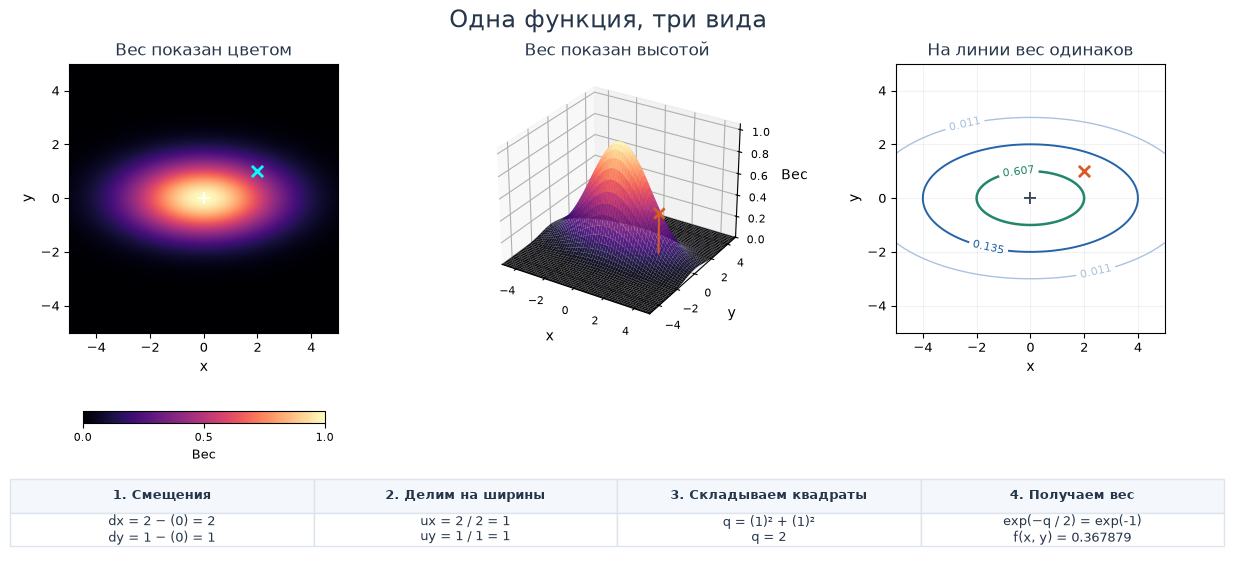

In [2]:
display(plane_figure(language=LANG))
display(plane_lab(language=LANG))

Изменения параметров дают четыре разных опыта:

1. В примере **«Круг»** ширины по двум направлениям одинаковы, поэтому пятно одинаково расходится во все стороны.
2. В исходном примере ширина по $x$ равна 2, по $y$ — 1. Контуры растянуты вправо и влево. Вершина при этом остаётся на высоте 1.
3. Сдвинем центр по $y$ с 0 на 1. Пятно переедет вверх. Крестик пока стоит на прежнем месте, поэтому число под ним изменится.
4. После сброса меняем только «Точка: x» и «Точка: y». Само пятно теперь остаётся на месте; меняется лишь место измерения.

У всех трёх видов одна область координат: от −5 до 5. Высота ограничена одной и той же шкалой от 0 до 1, цветовая шкала тоже закреплена. Поэтому расширение пятна не прячется за автоматическим изменением масштаба рисунка.

Дальше считаем исходный пример: центр $(0,0)$, ширины 2 и 1, точка $(2,1)$.

## 2. Две координаты вместо одной

Запись $(2,1)$ читается по порядку: сначала $x=2$, затем $y=1$. От нуля идём на две единицы вправо и на одну вверх. В этом уроке положительный $y$ направлен вверх. У массивов изображений строки часто считают сверху вниз; это другое соглашение, которое понадобится позже при работе с пикселями.

У центра теперь тоже два числа: $(\mu_x,\mu_y)$. Маленькие буквы снизу называют **индексами**. Здесь индекс только уточняет направление: $\mu_x$ — «мю по икс», $\mu_y$ — «мю по игрек». Умножения на $x$ или $y$ в этих записях нет.

| Запись | Как читать | Наши числа |
|---|---|---|
| $(x,y)$ | Координаты точки | $(2,1)$ |
| $(\mu_x,\mu_y)$ | Координаты центра | $(0,0)$ |
| $\sigma_x$ | «сигма по икс», масштаб ширины по горизонтали | 2 |
| $\sigma_y$ | «сигма по игрек», масштаб ширины по вертикали | 1 |
| $f(x,y)$ | «эф от икс и игрек», вес в этой точке | Пока неизвестен |

Функция получает два числа и возвращает **одно**. Цвет на карте и высота холма показывают именно это одно число.

Координаты центра, точки и ширины будем измерять в одних единицах, например сантиметрах. В демонстрации единицы условные. Обе ширины должны быть больше нуля. Пока направления ширины совпадают с осями $x$ и $y$; поворачивать пятно будем в следующем уроке.

## 3. Возьмём по колоколу для каждого направления

Сначала временно забудем о вертикали. По горизонтали всё как в уроке 2:

$$
d_x=x-\mu_x=2-0=2,
\qquad u_x=\frac{d_x}{\sigma_x}=\frac{2}{2}=1.
$$

$d_x$ — смещение по горизонтали. $u_x$ — то же смещение, измеренное в ширинах. Два сантиметра при ширине два сантиметра — одна ширина. Дальше квадрат, деление на 2, минус и экспонента:

$$
w_x=\exp\left(-\frac{u_x^2}{2}\right)
=\exp\left(-\frac{1\cdot1}{2}\right)
=\exp(-0.5)\approx0.606531.
$$

$w_x$ — короткое имя веса, который получился **только по горизонтали**. Теперь повторим тот же расчёт для вертикали:

$$
d_y=y-\mu_y=1-0=1,
\qquad u_y=\frac{d_y}{\sigma_y}=\frac{1}{1}=1.
$$

$$
w_y=\exp\left(-\frac{u_y^2}{2}\right)
=\exp\left(-\frac{1\cdot1}{2}\right)
=\exp(-0.5)\approx0.606531.
$$

По горизонтали мы прошли две координатные единицы, по вертикали одну, но **в ширинах** оба смещения одинаковы. Поэтому два веса совпали.

Для нашего пятна перемножим их:

$$
f(x,y)=w_x\cdot w_y.
$$

Так удаление по любому направлению ослабляет общий вес. Если по одной оси мы попали ровно в центр, её вес равен 1, и умножение оставляет вес другой оси как есть. Если по обеим ушли от центра, два ослабления действуют вместе.

В точке $(2,1)$ получится примерно $0.606531\cdot0.606531\approx0.367879$. Для вычисления не будем перемножать уже округлённые числа: Python сохранит полную точность, а шесть знаков оставим только при печати.

In [3]:
ux = (2 - 0) / 2
uy = (1 - 0) / 1
weight_x = math.exp(-(ux * ux) / 2)
weight_y = math.exp(-(uy * uy) / 2)
print(f"wx = {weight_x:.6f}")
print(f"wy = {weight_y:.6f}")
print(f"wx * wy = {weight_x * weight_y:.6f}")

wx = 0.606531
wy = 0.606531
wx * wy = 0.367879


## 4. Почему в одной формуле появится сумма

Мы перемножили два веса, а в компактной записи увидим сложение. Это не смена способа расчёта. У степеней с одинаковым основанием при умножении **складываются показатели**.

На целых числах это видно по количеству множителей:

$$
2^2\cdot2^3=(2\cdot2)\cdot(2\cdot2\cdot2)=2^5=2^{2+3}.
$$

Степени с дробными и отрицательными показателями продолжают то же правило. Например, $e^{-0.5}=1/\sqrt{e}$, поэтому:

$$
e^{-0.5}\cdot e^{-0.5}
=\frac{1}{\sqrt{e}}\cdot\frac{1}{\sqrt{e}}
=\frac{1}{e}=e^{-1}.
$$

Два показателя $-0.5$ сложились и дали $-1$. В общем виде правило выглядит так: $e^a\cdot e^b=e^{a+b}$. Буквы $a$ и $b$ здесь обозначают любые два показателя степени.

Подставим вместо них наши выражения. Весь переход можно прочитать построчно:

$$
\begin{aligned}
f(x,y)&=\exp\left(-\frac{u_x^2}{2}\right)\cdot\exp\left(-\frac{u_y^2}{2}\right)\\
&=\exp\left(-\frac{u_x^2}{2}-\frac{u_y^2}{2}\right)\\
&=\exp\left(-\frac{u_x^2+u_y^2}{2}\right).
\end{aligned}
$$

В последней строке у двух дробей одинаковый знаменатель 2. Мы сложили числители и оставили общее деление. Складываются **квадраты смещений внутри показателя**, а не готовые веса снаружи экспоненты.

## 5. Собираем формулу и читаем её изнутри

Теперь заменим $u_x$ и $u_y$ их расшифровками:

$$
f(x,y)=\exp\left[-\frac12\left(
\left(\frac{x-\mu_x}{\sigma_x}\right)^2+
\left(\frac{y-\mu_y}{\sigma_y}\right)^2
\right)\right].
$$

Квадратные скобки здесь работают как обычные круглые: группируют то, к чему применяется экспонента. Дроби отвечают за два направления. Маленькая двойка относится **ко всей дроби**, включая её знаменатель.

Читаем по действиям:

1. Вычитаем центр отдельно из $x$ и из $y$.
2. Делим каждое смещение на ширину **своего** направления.
3. Возводим оба полученных числа в квадрат.
4. Складываем эти два квадрата.
5. Делим сумму на 2, ставим минус и вычисляем экспоненту.

Сумму квадратов назовём $q$, чтобы удобнее следить за промежуточным числом:

$$
q=u_x^2+u_y^2,
\qquad f(x,y)=\exp(-q/2).
$$

$u_x$ и $u_y$ безразмерны: сантиметры сократились при делении на сантиметры. Их квадраты, сумма $q$, показатель $-q/2$ и итоговый вес тоже не имеют единиц длины.

В центре оба смещения равны нулю. Тогда $q=0^2+0^2=0$ и $f(\mu_x,\mu_y)=e^0=1$. Уход в любую сторону делает хотя бы один квадрат положительным; показатель становится отрицательным, а вес — меньше 1. Изменяя ширины, мы пока сохраняем вершину 1.

## 6. Пройдём точку $(2,1)$ без сокращений

Центр $(0,0)$, ширины $\sigma_x=2$, $\sigma_y=1$. Обе координаты и ширины записаны в одних единицах.

| Шаг | По горизонтали | По вертикали |
|---|---|---|
| Вычитаем центр | $d_x=2-0=2$ | $d_y=1-0=1$ |
| Делим на свою ширину | $u_x=2/2=1$ | $u_y=1/1=1$ |
| Возводим в квадрат | $u_x^2=1\cdot1=1$ | $u_y^2=1\cdot1=1$ |

Теперь две ветки соединяются:

$$
q=1+1=2,\qquad -q/2=-2/2=-1,
\qquad f(2,1)=e^{-1}\approx0.367879.
$$

На тепловой карте этому числу соответствует цвет под крестиком. На холме — высота отмеченной точки. На контурном рисунке точка лежит между линиями с весами примерно 0.607 и 0.135.

Перенесём каждое действие в отдельную строку Python. `qx` и `qy` хранят квадраты, `exponent` — показатель степени, `weight` — итоговый вес. Здесь `*` означает умножение, `/` — деление, а `=` сохраняет правую часть в переменную слева.

In [4]:
x, y = 2.0, 1.0
mux, muy = 0.0, 0.0
sx, sy = 2.0, 1.0

dx = x - mux
dy = y - muy
ux = dx / sx
uy = dy / sy
qx = ux * ux
qy = uy * uy
q = qx + qy
exponent = -q / 2
weight = math.exp(exponent)

print(f"dx = {dx:.1f}, dy = {dy:.1f}")
print(f"ux = {ux:.1f}, uy = {uy:.1f}")
print(f"qx = {qx:.1f}, qy = {qy:.1f}")
print(f"q = {q:.1f}, exponent = {exponent:.1f}")
print(f"weight = {weight:.6f}")

dx = 2.0, dy = 1.0
ux = 1.0, uy = 1.0
qx = 1.0, qy = 1.0
q = 2.0, exponent = -1.0
weight = 0.367879


## 7. От круга к эллипсу

Справа на первом рисунке проведены линии одинакового веса. Возьмём одну из них: ту, где вес равен $e^{-1/2}\approx0.606531$. Мы уже знаем, что такой вес получается при $q=1$. Значит, точки нужной линии удовлетворяют условию:

$$
\left(\frac{x-\mu_x}{\sigma_x}\right)^2+
\left(\frac{y-\mu_y}{\sigma_y}\right)^2=1.
$$

Слово **контур** здесь означает линию одинакового значения. Переход через неё не выключает гауссиану: за линией вес продолжает уменьшаться.

Когда обе ширины равны 1 и центр в нуле, условие превращается в $x^2+y^2=1$. Это окружность радиуса 1. Связь с расстоянием даёт теорема Пифагора: квадрат диагонали прямоугольного треугольника равен сумме квадратов двух его сторон. Например, для перемещений на 3 вправо и 4 вверх получится $3^2+4^2=9+16=25$, то есть расстояние до начала $\sqrt{25}=5$. Поэтому одинаковая сумма $x^2+y^2$ означает одинаковое расстояние до начала.

Теперь растянем горизонтальное направление вдвое: $\sigma_x=2$, $\sigma_y=1$. Точке $(2,0)$ после деления достаются координаты $(1,0)$; точке $(0,1)$ — $(0,1)$. Обе дают сумму квадратов 1. В исходных координатах круг стал **эллипсом**.

На выбранном контуре расстояние от центра до правой точки равно $\sigma_x$, а до верхней — $\sigma_y$. Эти отрезки называют **полуосями**. Полная ширина этого контура по горизонтали — $2\sigma_x$, по вертикали — $2\sigma_y$. Это размеры конкретной линии уровня; у всего мягкого пятна конечной границы по-прежнему нет.

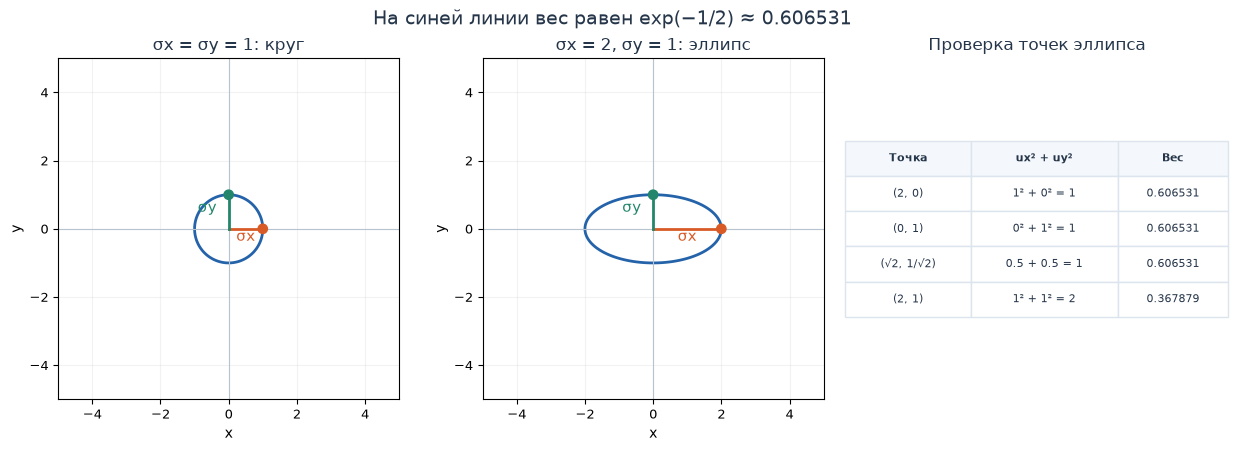

In [5]:
display(ellipse_figure(language=LANG))

Проверим не только крайние точки, но и точку между ними. В таблице на рисунке для эллипса взята $(\sqrt{2},1/\sqrt{2})$, примерно $(1.414214,0.707107)$.

Для неё:

$$
u_x=\frac{\sqrt{2}}{2}=\frac{1}{\sqrt{2}},
\qquad u_y=\frac{1/\sqrt{2}}{1}=\frac{1}{\sqrt{2}}.
$$

Первое равенство можно проверить умножением на $\sqrt{2}$: слева получится $\sqrt{2}\cdot\sqrt{2}/2=2/2=1$, справа тоже 1. После возведения в квадрат каждое число даёт $1/2$:

$$
q=\left(\frac{1}{\sqrt{2}}\right)^2+
\left(\frac{1}{\sqrt{2}}\right)^2
=\frac12+\frac12=1.
$$

Вес снова $e^{-1/2}\approx0.606531$: точка лежит на том же контуре.

А вот $(2,1)$ даёт $1^2+1^2=2$ и вес примерно 0.367879. Если пройти на одну ширину **по каждой** оси сразу, окажемся дальше от центра, чем на одну ширину только по одной оси. Угол прямоугольника с полуосями 2 и 1 находится за эллипсом.

Число 0.606531 здесь означает примерно 61% **веса в вершине**. Оно не говорит, что внутри эллипса лежит 61% площади или вероятности.

## 8. Разрежем пятно и узнаем старый колокол

На тепловой карте можно провести горизонтальную линию и двигаться только по ней. Тогда $y$ закреплён, а $x$ меняется. Это **срез** функции: мы смотрим на плоскость вдоль одной выбранной линии.

Если линия проходит через центр, $y=\mu_y$, то вертикальное смещение равно нулю, $u_y=0$ и $w_y=e^0=1$. Получаем:

$$
f(x,\mu_y)=w_x\cdot1=w_x.
$$

Перед нами ровно одномерная гауссиана из прошлого урока. Её центр по $x$ равен $\mu_x$, ширина — $\sigma_x$, вершина — 1.

Но срез не обязан проходить через вершину. Закрепим $y=1$ при $\mu_y=0$, $\sigma_y=1$. Тогда $u_y=(1-0)/1=1$, и **для всех** точек этой горизонтальной линии $w_y=e^{-1/2}\approx0.606531$. Он просто умножает весь горизонтальный колокол:

$$
f(x,1)=w_x\cdot0.606531\ldots
$$

Его вершина теперь примерно 0.606531, хотя вершина полной двумерной функции всё ещё 1 — она осталась в $(0,0)$, за пределами выбранной линии. Ширина среза по $x$ не изменилась.

С вертикальным срезом всё аналогично. При закреплённом $x=2$ горизонтальный вес $w_x\approx0.606531$ умножает вертикальный колокол. Оба среза пересекаются в $(2,1)$ и в этом месте обязаны показать один вес, примерно 0.367879.

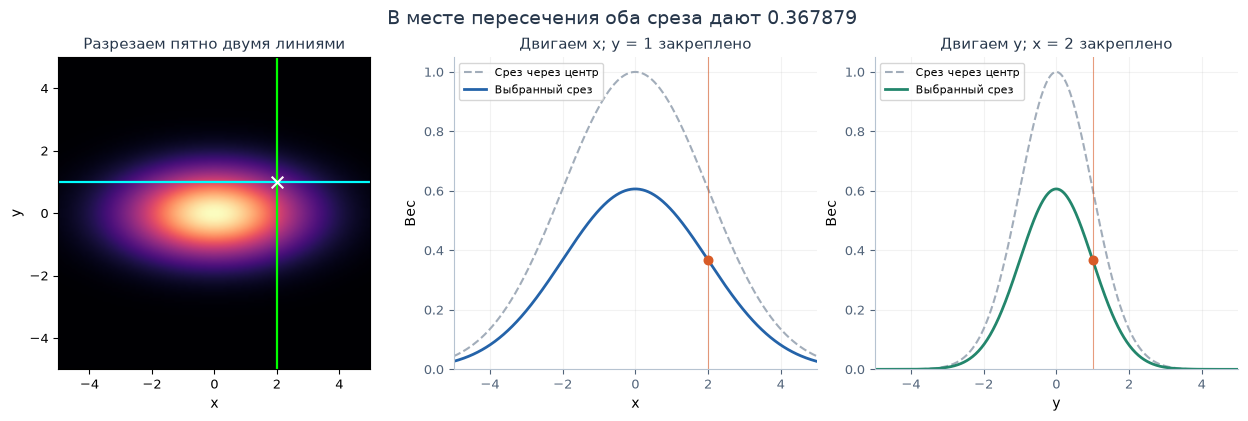

In [6]:
display(slices_figure(mux=0, muy=0, sx=2, sy=1, x=2, y=1, language=LANG))

## 9. Меняем одно число и следим за причиной

Вернём точку $(2,1)$, центр $(0,0)$ и ширины 2 и 1. До изменений вес равен примерно 0.367879.

**Сузим только горизонтальное направление до $\sigma_x=1$.** Смещения остались $d_x=2$, $d_y=1$. Но теперь $u_x=2/1=2$, а $u_y=1/1=1$. Тогда $q=2^2+1^2=4+1=5$, показатель $-5/2=-2.5$, вес $e^{-2.5}\approx0.082085$. Точка стала дальше в единицах новой горизонтальной ширины.

**Вернём $\sigma_x=2$ и расширим вертикаль до $\sigma_y=2$.** Получаем $u_x=2/2=1$, $u_y=1/2=0.5$. Квадраты 1 и 0.25 дают $q=1.25$, показатель $-1.25/2=-0.625$, вес $e^{-0.625}\approx0.535261$. По вертикали та же точка теперь ближе к центру в ширинах, поэтому общий вес вырос.

**Вернём ширины 2 и 1 и перенесём центр в $(1,-1)$.** Для прежней точки $(2,1)$ смещения будут $d_x=2-1=1$, $d_y=1-(-1)=2$. Отсюда $u_x=1/2=0.5$, $u_y=2/1=2$, сумма $q=0.25+4=4.25$, показатель $-2.125$, вес примерно 0.119433.

Если вместе с центром перенести и точку на то же смещение $(1,-1)$, она попадёт в $(3,0)$. Тогда разности снова будут $3-1=2$ и $0-(-1)=1$, а вес вернётся к 0.367879. Важны расстояния **от центра**, а не расположение всей конструкции относительно нуля.

## 10. Функция для любой точки

Теперь соберём расчёт в функцию. Она получает две координаты точки, две координаты центра и две ширины. Все шесть чисел должны быть конечными, обе ширины — положительными.

Проверка `math.isfinite` отсекает бесконечность и `NaN`, специальное обозначение неопределённого числа. `all` проверяет, что условие выполнено для каждого из шести значений. Дальше идут те же действия, которые мы уже считали вручную.

In [7]:
def plane_weight(x, y, mux, muy, sx, sy):
    if not all(math.isfinite(v) for v in (x, y, mux, muy, sx, sy)):
        raise ValueError("Use finite coordinates and scales.")
    if sx <= 0 or sy <= 0:
        raise ValueError("Both scales must be greater than zero.")

    dx = x - mux
    dy = y - muy
    ux = dx / sx
    uy = dy / sy
    qx = ux * ux
    qy = uy * uy
    q = qx + qy
    return math.exp(-q / 2)


for x, y in [(0, 0), (2, 0), (0, 1), (2, 1), (-2, -1)]:
    weight = plane_weight(x, y, mux=0, muy=0, sx=2, sy=1)
    print(f"({x:2}, {y:2}) -> {weight:.6f}")

( 0,  0) -> 1.000000
( 2,  0) -> 0.606531
( 0,  1) -> 0.606531
( 2,  1) -> 0.367879
(-2, -1) -> 0.367879


В демонстрации получаются те же числа. Последняя точка $(-2,-1)$ — отражение $(2,1)$ относительно центра. Смещения поменяли знаки, но их квадраты совпали, поэтому совпал и вес.

При нулевой ширине функция выдаст `ValueError`: делить на ноль нельзя. Вызов `plane_weight(2, 1, 0, 0, 0, 1)` показывает эту проверку в действии: вместо веса получаем сообщение об ошибочном вводе. С положительной шириной расчёт снова работает.

На экране мы видим только квадрат от −5 до 5. У самой гауссианы нет края на границе этого квадрата. Например, за тремя ширинами вес уже мал, но математически остаётся положительным. Очень маленькие результаты компьютер может округлить до нуля — с этим мы встречались в прошлом уроке.

Мы пока задаём пространственный вес с вершиной 1. Цвета, непрозрачность и перекрытия нескольких пятен появятся в уроке 5. Никакого обучения здесь ещё нет: все параметры меняем сами.

## 11. Несколько проверок без подсказки ползунка

Для всех заданий, кроме явно указанных изменений: центр $(0,0)$, ширины $\sigma_x=2$, $\sigma_y=1$. В каждом опыте сначала можно предположить результат, затем проверить его расчётом и на рисунке.

### 1. Две разные точки — один вес

В точках $(2,0)$ и $(0,1)$ вес одинаковый или где-то больше?

<details>
<summary>Разбор</summary>

В первой точке $u_x=2/2=1$, $u_y=0/1=0$, поэтому $q=1^2+0^2=1$. Во второй $u_x=0/2=0$, $u_y=1/1=1$, поэтому $q=0^2+1^2=1$. В обоих случаях показатель $-1/2=-0.5$ и вес $e^{-0.5}\approx0.606531$. Координатные расстояния отличаются, но масштаб каждого направления это учитывает.

</details>

### 2. Доходим до угла

Если обе предыдущие точки лежат на контуре 0.606531, будет ли на нём и точка $(2,1)$?

<details>
<summary>Разбор</summary>

Для $(2,1)$ получаем $u_x=1$, $u_y=1$, затем $q=1+1=2$. Показатель $-2/2=-1$, вес $e^{-1}\approx0.367879$. Эта точка уже за выбранным контуром. Два ухода от центра учитываются вместе.

</details>

### 3. Передвинули всё вместе

Центр стал $(1,-1)$, точка — $(3,0)$. Ширины прежние. Изменится ли вес по сравнению с исходной точкой $(2,1)$ при центре $(0,0)$?

<details>
<summary>Разбор</summary>

Новые смещения $3-1=2$ и $0-(-1)=1$ совпали с исходными. Деление на ширины снова даёт 1 и 1, сумма квадратов 2, показатель −1, вес примерно 0.367879. Совместный перенос сохранил положение точки относительно пятна.

</details>

### 4. Срез прошёл мимо вершины

Для среза с закреплённым $y=2$ какова максимальная высота? Какой вес он покажет при $x=2$?

<details>
<summary>Разбор</summary>

Вертикальное смещение $d_y=2-0=2$, относительное $u_y=2/1=2$, квадрат 4, вес по вертикали $w_y=e^{-4/2}=e^{-2}\approx0.135335$.

Максимум горизонтального веса достигается при $x=\mu_x=0$ и равен 1. Поэтому вершина среза $1\cdot0.135335\approx0.135335$. При $x=2$ горизонтальное смещение в ширинах равно 1; общий $q=1^2+2^2=5$, показатель −2.5, вес примерно 0.082085. Низкий срез не означает, что пропала вершина всего холма.

</details>

### 5. А если сложить готовые веса?

Вместо произведения возьмём $(w_x+w_y)/2$. В центре получится 1 — вроде бы всё хорошо. Что получится в точке $(0,3)$?

<details>
<summary>Разбор</summary>

По горизонтали $u_x=0$, поэтому $w_x=1$. По вертикали $u_y=3/1=3$, квадрат 9, показатель $-9/2=-4.5$, поэтому $w_y\approx0.011109$.

Среднее даст $(1+0.011109)/2\approx0.505555$: половина вершины даже далеко по вертикали. Произведение даст $1\cdot0.011109=0.011109$. Среднее оставляет длинные заметные полосы вдоль осей, потому что большой вес одного направления компенсирует маленький вес другого. Мы выбрали произведение именно для пятна, которое затухает при удалении по любому направлению.

</details>

## 12. Что добавилось к одномерному колоколу

Мы повторили знакомый расчёт для двух направлений и соединили результаты. Теперь можно взять точку на цветной карте, найти её на холме и объяснить её вес через два смещения и две ширины. Видимый эллипс связан с теми же числами, что стоят в формуле.

Пока эллипс привязан к горизонтали и вертикали. В [уроке 4](lesson-04.ipynb) повернём его. Там появится ковариационная матрица, но начнём снова с картинки и нескольких точек: посмотрим, какие числа нужно хранить, чтобы описать уже знакомую форму после поворота.